# Model: Prediction of a patient's body fat percentage
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Body Fat Prediction Dataset (Kaggle, fedesoriano)](https://www.kaggle.com/fedesoriano/body-fat-prediction-dataset) — data from Johnson (1996) | **Type:** regression

This notebook follows the project template and leaves the model ready for the API (`models/body_fat.joblib` + `predictors/body_fat.py`).

Voice command: *"JarvisTEC, body fat of a 43 year old man with abdomen 91 and wrist 18.3"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** A person's **body fat percentage** from measurements taken with a tape measure. It serves to answer commands such as *"JarvisTEC, calculate the patient's body fat"*.

**Why does it matter?** The reference measurement consists of weighing the person submerged in water to obtain their density and applying Siri's equation (1956). It is accurate but uncomfortable and expensive. Johnson (1996), the source of this data, poses exactly this problem: estimating fat with a scale and a tape measure through multiple regression.

**Design decisions**
- **Without density:** the `Density` column is the measurement from which fat is computed. Using it would be giving the model the answer, and it is also precisely what we want to avoid measuring.
- **Metrics:** mean absolute error (MAE) and RMSE, in body-fat points, and R².
- **Success criterion:** clearly beat the baseline that always answers the mean, and do it with few measurements so it can be used by dictating the data by voice.

## 2. Data understanding (0.5 pt)

Each row is an adult man: 252, with 15 columns, all numeric and without nulls.

| Column | Meaning |
|---|---|
| `BodyFat` | **Target.** Body fat percentage, computed from the density with Siri's equation |
| `Density` | Body density measured by underwater weighing. **Not used** as an input |
| `Age` | Age in years |
| `Weight`, `Height` | Weight and height (given in pounds and inches) |
| `Neck`, `Chest`, `Abdomen`, `Hip`, `Thigh`, `Knee`, `Ankle`, `Biceps`, `Forearm`, `Wrist` | Circumference of neck, chest, abdomen, hip, thigh, knee, ankle, biceps, forearm and wrist, in centimeters |

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '..')          # to import predictors/

import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RepeatedKFold, KFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
BLUE, ORANGE, GRAY = '#2563eb', '#ea580c', '#94a3b8'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'font.size': 9, 'legend.frameon': False})
print('scikit-learn', sklearn.__version__)

data = pd.read_csv('../data/bodyfat.csv')
print('Rows:', data.shape[0], '| columns:', data.shape[1], '| nulls:', int(data.isna().sum().sum()), '| duplicates:', data.duplicated().sum())
data.head()

scikit-learn 1.8.0
Rows: 252 | columns: 15 | nulls: 0 | duplicates: 0


,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


In [2]:
# Weight comes in pounds and height in inches: they are converted to kilograms and centimeters, like the other measurements
data['Weight'] = (data.Weight * 0.45359237).round(1)
data['Height'] = (data.Height * 2.54).round(1)
data.describe().round(1)

,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
count,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0,252.0
mean,1.1,19.2,44.9,81.2,178.2,38.0,100.8,92.6,99.9,59.4,38.6,23.1,32.3,28.7,18.2
std,0.0,8.4,12.6,13.3,9.3,2.4,8.4,10.8,7.2,5.2,2.4,1.7,3.0,2.0,0.9
min,1.0,0.0,22.0,53.8,74.9,31.1,79.3,69.4,85.0,47.2,33.0,19.1,24.8,21.0,15.8
25%,1.0,12.5,35.8,72.1,173.4,36.4,94.4,84.6,95.5,56.0,37.0,22.0,30.2,27.3,17.6
50%,1.1,19.2,43.0,80.1,177.8,38.0,99.6,91.0,99.3,59.0,38.5,22.8,32.0,28.7,18.3
75%,1.1,25.3,54.0,89.4,183.5,39.4,105.4,99.3,103.5,62.4,39.9,24.0,34.3,30.0,18.8
max,1.1,47.5,81.0,164.7,197.5,51.2,136.2,148.1,147.7,87.3,49.1,33.9,45.0,34.9,21.4


## 3. Data exploration (0.5 pt)
Typing errors, distribution of the target, relation of each measurement with fat and relation of the measurements among themselves.

In [3]:
# Typing errors: fat was computed from the density with Siri's equation,
# so the two columns must agree; and nobody is shorter than one meter
siri = 495 / data.Density - 450
odd = (data.Height < 100) | ((data.BodyFat - siri).abs() > 2)
print('Correlation between BodyFat and Siri equation in the rest:', round(data.BodyFat[~odd].corr(siri[~odd]), 4))
print(data.loc[odd, ['Density', 'BodyFat', 'Weight', 'Height']].assign(Siri=siri[odd].round(1), case=data.index[odd] + 1).to_string(index=False))

data = data[~odd].reset_index(drop=True)
print('\n', len(data), 'men remain | body fat: mean', round(data.BodyFat.mean(), 1), '| std', round(data.BodyFat.std(), 1),
      '| min', data.BodyFat.min(), '| max', data.BodyFat.max())

Correlation between BodyFat and Siri equation in the rest: 0.9999
 Density  BodyFat  Weight  Height  Siri  case
  1.0250     32.9    93.0    74.9  32.9    42
  1.0665      5.6    67.4   181.0  14.1    48
  1.0666     18.5    67.2   171.4  14.1    76
  1.0991     17.4   101.8   197.5   0.4    96
  1.1089      0.0    53.8   172.7  -3.6   182

 247 men remain | body fat: mean 19.2 | std 8.3 | min 0.7 | max 47.5


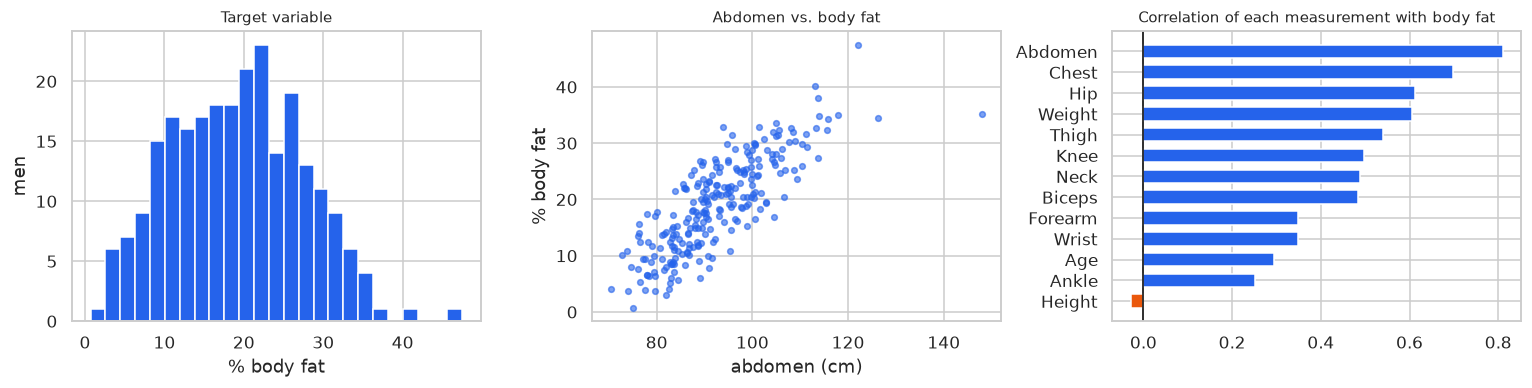

{'Abdomen': 0.81, 'Chest': 0.7, 'Hip': 0.61, 'Weight': 0.61, 'Thigh': 0.54, 'Knee': 0.5, 'Neck': 0.49, 'Biceps': 0.48, 'Forearm': 0.35, 'Wrist': 0.35, 'Age': 0.29, 'Ankle': 0.25, 'Height': -0.03}


In [4]:
MEASUREMENTS = [c for c in data.columns if c not in ('Density', 'BodyFat')]
correl = data[MEASUREMENTS].corrwith(data.BodyFat).sort_values()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(data.BodyFat, bins=25, color=BLUE)
ax[0].set_xlabel('% body fat'); ax[0].set_ylabel('men'); ax[0].set_title('Target variable')
ax[1].scatter(data.Abdomen, data.BodyFat, s=14, alpha=0.6, color=BLUE)
ax[1].set_xlabel('abdomen (cm)'); ax[1].set_ylabel('% body fat'); ax[1].set_title('Abdomen vs. body fat')
ax[2].barh(correl.index, correl.values, color=[BLUE if v > 0 else ORANGE for v in correl.values], height=0.65)
ax[2].axvline(0, color='black', lw=1); ax[2].set_title('Correlation of each measurement with body fat')
plt.tight_layout(); plt.show()
print(correl.sort_values(ascending=False).round(2).to_dict())

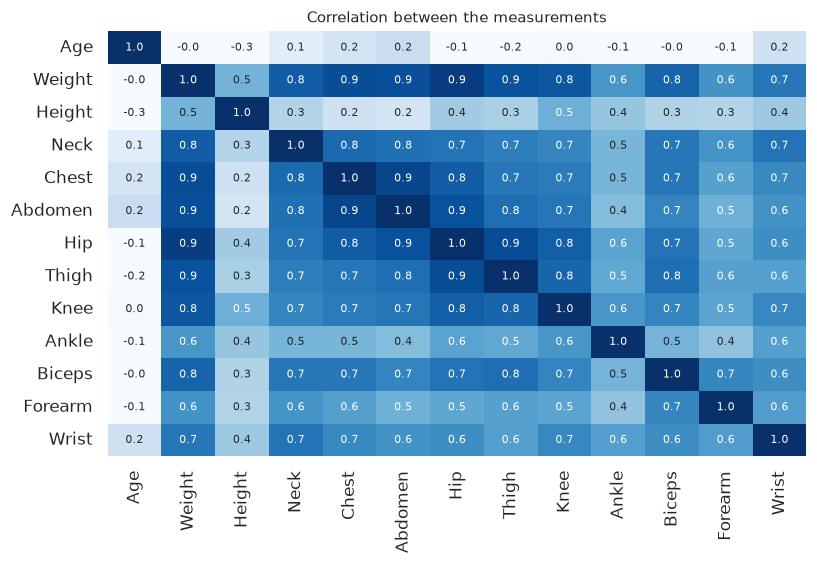

Most correlated pairs: {'Weight-Hip': 0.94, 'Chest-Abdomen': 0.91, 'Hip-Thigh': 0.89, 'Weight-Chest': 0.89, 'Weight-Abdomen': 0.89}
Pairs with correlation above 0.8: 11 of 78


In [5]:
# The measurements are very similar to each other
between = data[MEASUREMENTS].corr()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.heatmap(between, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=1, cbar=False, annot_kws={'size': 7}, ax=ax)
ax.set_title('Correlation between the measurements'); plt.tight_layout(); plt.show()
pairs = between.where(np.triu(np.ones(between.shape, dtype=bool), k=1)).stack().dropna().sort_values(ascending=False)
print('Most correlated pairs:', {f'{a}-{b}': round(v, 2) for (a, b), v in pairs.head(5).items()})
print('Pairs with correlation above 0.8:', int((pairs > 0.8).sum()), 'of', len(pairs))

**Findings**
- **Five rows with errors.** In the rest of the data `BodyFat` reproduces Siri's equation almost exactly (correlation 0.9999), but in four cases it does not match the density, and in one of them the fat is 0%, which is impossible. Another case is 75 cm tall with 93 kg. They are the same five cases (42, 48, 76, 96 and 182) that Johnson (1996) reports as typing errors. They are removed: 247 men remain.
- The target is bell-shaped, with a mean of 19.2% and a standard deviation of 8.3 points; it needs no transformation.
- **The abdomen is the measurement that says the most** (correlation 0.81); it is followed by the chest (0.70), the hip and the weight (0.61). Height alone says nothing (−0.03).
- **The measurements repeat each other a lot:** 11 pairs have a correlation above 0.8 (weight and hip, 0.94; chest and abdomen, 0.91). With such similar variables a linear regression spreads the effect among them unstably; that is why **Lasso** is tried, which sets to zero the coefficients that add nothing (Tibshirani, 1996).

## 4. Model (2 pts)

**Preprocessing:** standardization inside a `Pipeline` for the linear models (Lasso penalizes the coefficients, so all the measurements must be on the same scale). Trees do not need it.

**Split:** 80% training and 20% test (50 men).

**Algorithms compared**, tuned with `GridSearchCV` (5-fold cross-validation repeated 5 times, minimizing the MAE):
- **Linear regression** with the 13 measurements: it is Johnson's (1996) approach.
- **Lasso** (Tibshirani, 1996): linear regression that eliminates measurements.
- **Random Forest** (Breiman, 2001).
- **Gradient Boosting** (Friedman, 2001).

In Lasso, the `alpha` penalty is chosen with the **one-standard-error rule** (Hastie et al., 2009): instead of the value with the lowest error, the strongest one whose error is practically the same. That leaves the simplest model that does not lose accuracy.

In [6]:
X = data[MEASUREMENTS]
y = data['BodyFat']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
print('Training:', len(X_tr), '| test:', len(X_te))

def scaled(model): return Pipeline([('scale', StandardScaler()), ('model', model)])
def direct(model):  return Pipeline([('model', model)])

folds = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
grids = {
    'Linear regression': (scaled(LinearRegression()), {}),
    'Lasso':             (scaled(Lasso(max_iter=50000)), {'model__alpha': [0.01, 0.03, 0.1, 0.2, 0.3, 0.5, 1.0]}),
    'Random Forest':     (direct(RandomForestRegressor(300, random_state=SEED, n_jobs=-1)),
                          {'model__min_samples_leaf': [1, 3, 5], 'model__max_features': [0.33, 0.5, 1.0]}),
    'Gradient Boosting': (direct(GradientBoostingRegressor(subsample=0.8, random_state=SEED)),
                          {'model__n_estimators': [100, 300], 'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=folds, scoring='neg_mean_absolute_error', n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs
    print(f'{name:18s} CV MAE: {-gs.best_score_:.2f} ± {gs.cv_results_["std_test_score"][gs.best_index_]:.2f} | best parameters: {gs.best_params_}')

Training: 197 | test: 50


Linear regression  CV MAE: 3.74 ± 0.33 | best parameters: {}


Lasso              CV MAE: 3.68 ± 0.31 | best parameters: {'model__alpha': 0.2}


Random Forest      CV MAE: 3.96 ± 0.36 | best parameters: {'model__max_features': 1.0, 'model__min_samples_leaf': 5}


Gradient Boosting  CV MAE: 3.73 ± 0.30 | best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300}


In [7]:
# Lasso: which measurements it keeps depending on the penalty (alpha)
gs = best['Lasso']
path = pd.DataFrame({'alpha': [float(a) for a in gs.cv_results_['param_model__alpha']],
                     'mae': -gs.cv_results_['mean_test_score'],
                     'se': gs.cv_results_['std_test_score'] / np.sqrt(folds.get_n_splits())})
for row in path.itertuples():
    coef = pd.Series(scaled(Lasso(alpha=row.alpha, max_iter=50000)).fit(X_tr, y_tr)[-1].coef_, index=MEASUREMENTS)
    print(f'alpha {row.alpha:<5} CV MAE {row.mae:.2f} | {int((coef != 0).sum()):2d} measurements: {list(coef[coef != 0].index)}')

# One-standard-error rule: the strongest penalty whose error is within one standard error of the best
limit = path.mae.min() + path.se[path.mae.idxmin()]
ALPHA = path.alpha[path.mae <= limit].max()
print(f'\nBest MAE {path.mae.min():.2f} | limit {limit:.2f} | chosen alpha: {ALPHA}')

alpha 0.01  CV MAE 3.74 | 13 measurements: ['Age', 'Weight', 'Height', 'Neck', 'Chest', 'Abdomen', 'Hip', 'Thigh', 'Knee', 'Ankle', 'Biceps', 'Forearm', 'Wrist']
alpha 0.03  CV MAE 3.73 | 13 measurements: ['Age', 'Weight', 'Height', 'Neck', 'Chest', 'Abdomen', 'Hip', 'Thigh', 'Knee', 'Ankle', 'Biceps', 'Forearm', 'Wrist']
alpha 0.1   CV MAE 3.71 |  9 measurements: ['Age', 'Height', 'Neck', 'Chest', 'Abdomen', 'Ankle', 'Biceps', 'Forearm', 'Wrist']
alpha 0.2   CV MAE 3.68 |  5 measurements: ['Age', 'Height', 'Abdomen', 'Biceps', 'Wrist']
alpha 0.3   CV MAE 3.69 |  4 measurements: ['Age', 'Height', 'Abdomen', 'Wrist']
alpha 0.5   CV MAE 3.75 |  4 measurements: ['Age', 'Height', 'Abdomen', 'Wrist']
alpha 1.0   CV MAE 3.97 |  2 measurements: ['Height', 'Abdomen']

Best MAE 3.68 | limit 3.75 | chosen alpha: 0.3


## 5. Evaluation (1 pt)
Metrics on the test set (mean absolute error and RMSE in body-fat points, and R²), comparison between models and charts. Since the test set has few cases, a cross-validation over all the data is added, where each man is predicted with a model that did not see him.

In [8]:
def measure(actual, pred):
    return {'MAE': mean_absolute_error(actual, pred), 'RMSE': np.sqrt(mean_squared_error(actual, pred)), 'R²': r2_score(actual, pred)}

models = {'Baseline (the mean)': DummyRegressor().fit(X_tr, y_tr), **{n: gs.best_estimator_ for n, gs in best.items()},
          'Lasso': scaled(Lasso(alpha=ALPHA, max_iter=50000)).fit(X_tr, y_tr)}      # the Lasso of the one-standard-error rule
test_table = pd.DataFrame({n: measure(y_te, m.predict(X_te)) for n, m in models.items()}).T.round(2)
cv_table = pd.Series({n: -gs.best_score_ for n, gs in best.items()}, name='CV MAE')
cv_table['Lasso'] = path.mae[path.alpha == ALPHA].iloc[0]
cv_table = cv_table.round(2)
print('CV MAE:', cv_table.to_dict())
chosen = cv_table.idxmin()
print('Selected model (lowest cross-validated MAE):', chosen)
test_table

CV MAE: {'Linear regression': 3.74, 'Lasso': 3.69, 'Random Forest': 3.96, 'Gradient Boosting': 3.73}
Selected model (lowest cross-validated MAE): Lasso


,MAE,RMSE,R²
Baseline (the mean),6.58,7.75,-0.01
Linear regression,3.59,4.58,0.65
Lasso,3.70,4.89,0.60
Random Forest,3.41,4.37,0.68
Gradient Boosting,3.42,4.43,0.67


Measurements of the final model: ['Age', 'Height', 'Abdomen', 'Wrist'] | same predictions as with the 13: True
Cross-validation on all the data: {'MAE': 3.74, 'RMSE': 4.6, 'R²': 0.69}
Men with an error above 5 points: 30% | above 8 points: 6%


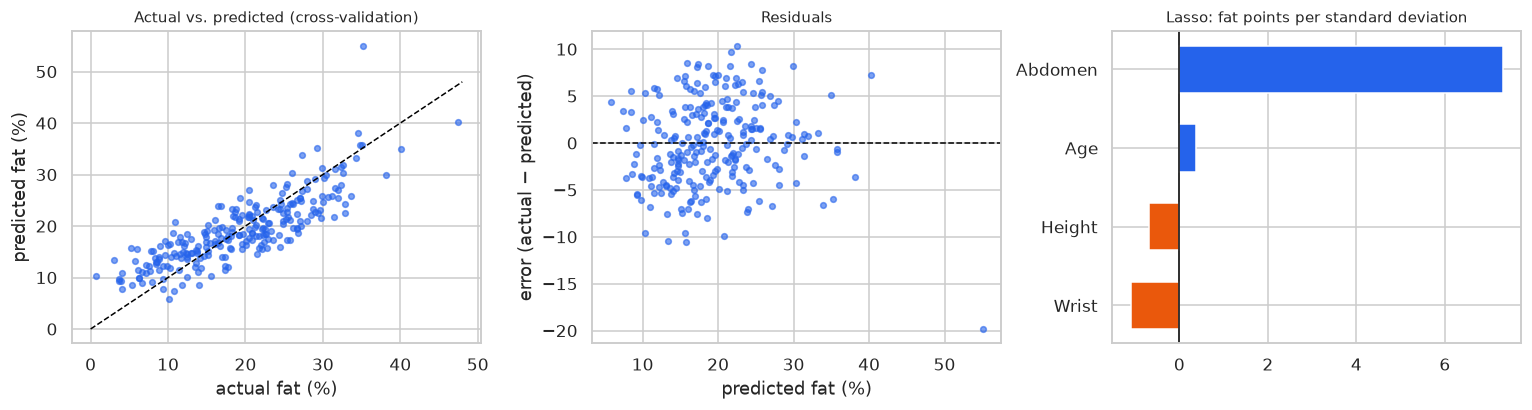

Coefficients: {'Abdomen': 7.31, 'Age': 0.39, 'Height': -0.69, 'Wrist': -1.09}
            men  mean error (actual − predicted)   MAE
BodyFat                                               
below 12 %   55                            -4.41  4.87
12 to 25 %  127                             0.28  2.84
above 25 %   65                             3.04  4.56


In [9]:
# The final model is the same Lasso, trained only with the measurements it keeps: it gives the same predictions
COLUMNS = [c for c, w in zip(MEASUREMENTS, models['Lasso'][-1].coef_) if w != 0] if chosen == 'Lasso' else MEASUREMENTS
final = clone(models[chosen]).fit(X_tr[COLUMNS], y_tr)
pred_te = final.predict(X_te[COLUMNS])
print('Measurements of the final model:', COLUMNS, '| same predictions as with the 13:', bool(np.allclose(pred_te, models[chosen].predict(X_te), atol=1e-3)))

pred_cv = pd.Series(cross_val_predict(final, X[COLUMNS], y, cv=KFold(5, shuffle=True, random_state=SEED)), index=y.index)
cv_summary = measure(y, pred_cv)
print('Cross-validation on all the data:', {k: round(float(v), 2) for k, v in cv_summary.items()})
print('Men with an error above 5 points:', f'{((y - pred_cv).abs() > 5).mean():.0%}', '| above 8 points:', f'{((y - pred_cv).abs() > 8).mean():.0%}')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(y, pred_cv, s=14, alpha=0.6, color=BLUE)
ax[0].plot([0, 48], [0, 48], color='black', lw=1, ls='--')
ax[0].set_xlabel('actual fat (%)'); ax[0].set_ylabel('predicted fat (%)'); ax[0].set_title('Actual vs. predicted (cross-validation)')
ax[1].scatter(pred_cv, y - pred_cv, s=14, alpha=0.6, color=BLUE)
ax[1].axhline(0, color='black', lw=1, ls='--')
ax[1].set_xlabel('predicted fat (%)'); ax[1].set_ylabel('error (actual − predicted)'); ax[1].set_title('Residuals')
coef = pd.Series(getattr(final[-1], 'coef_', getattr(final[-1], 'feature_importances_', None)), index=COLUMNS).sort_values()
ax[2].barh(coef.index, coef.values, color=[BLUE if v > 0 else ORANGE for v in coef.values], height=0.6)
ax[2].axvline(0, color='black', lw=1); ax[2].set_title(f'{chosen}: fat points per standard deviation')
plt.tight_layout(); plt.show()
print('Coefficients:', coef.sort_values(ascending=False).round(2).to_dict())

# Does it make the same mistakes with lean men as with men with a lot of fat?
groups = pd.cut(y, [0, 12, 25, 60], labels=['below 12 %', '12 to 25 %', 'above 25 %'])
print(pd.DataFrame({'men': y.groupby(groups, observed=True).size(),
                    'mean error (actual − predicted)': (y - pred_cv).groupby(groups, observed=True).mean().round(2),
                    'MAE': (y - pred_cv).abs().groupby(groups, observed=True).mean().round(2)}).to_string())

**Reading the results**
- **A tie, and the simplest wins.** In cross-validation the three best are within hundredths (Lasso 3.69, Gradient Boosting 3.73, linear regression 3.74), with a variation between folds of ±0.3. On the test set the order changes (the two tree models have 3.4 and Lasso 3.7), but there are 50 men and those differences are not conclusive. **Lasso** is chosen because, with the same error, it needs **4 measurements instead of 13**: abdomen, wrist, height and age.
- **How wrong it is:** about **3.7 points** of fat on average (R² of 0.69 in cross-validation), versus 6.6 for the baseline. In 30% of the men the error is above 5 points and in 6% it is above 8.
- **How to read the coefficients:** the abdomen dominates; an abdomen one standard deviation larger (about 11 cm) adds 7 points of fat. The wrist and the height subtract: with the same abdomen, a taller man or one with wider bones has less fat. Age adds a little.
- **Where it is wrong:** it tends towards the center. For the leanest men (below 12% fat) it adds on average 4.4 points too many, and for those above 25% it gives 3 too few. It also fails with bodies outside the ordinary: for the heaviest man in the set (165 kg, abdomen of 148 cm) it predicts about 55% and he has 35%.

## 6. Conclusion (0.5 pt)

**How well does it work?** With four pieces of data anyone can measure at home (abdomen, wrist, height and age) it estimates body fat with a mean error of **3.7 points**, a little more than half the error of always answering the mean (6.6). It serves as a quick estimate, not as a clinical measurement.

**What was learned**
- More variables did not give a better model: 13 measurements very similar to each other add the same as 4 well chosen ones.
- The more complex models (Random Forest, Gradient Boosting) did not beat the linear ones in cross-validation: with 247 rows and an almost straight relationship, simplicity is enough.
- Checking the data before modeling paid off: there were five rows with errors, and the density column would have given a "perfect" and useless model.

**Limitations**
- There are only **adult men**. The model is not valid for women or minors.
- It is imprecise at the extremes: it overestimates the leanest men and underestimates those with a lot of fat.
- The "real" fat it was trained with is itself an estimate (Siri's equation from density).

**Possible improvements:** data on women and measurements that distinguish muscle from fat.

## Export the model
The chosen model is **retrained with all the data** and saved together with the typical value of each measurement, so the API can fill in what the user does not give.

In [10]:
final_model = clone(final).fit(X[COLUMNS], y)

bundle = {
    'pipeline': final_model, 'model': chosen, 'features': COLUMNS,
    'typical_values': {c: round(float(X[c].median()), 1) for c in COLUMNS},
    'sklearn': sklearn.__version__,
    'cv_metrics': {k: float(v) for k, v in cv_summary.items()}, 'test_metrics': test_table.loc[chosen].to_dict(),
}
joblib.dump(bundle, '../models/body_fat.joblib', compress=3)
print('Saved ../models/body_fat.joblib | scikit-learn', sklearn.__version__, '| measurements it uses:', bundle['features'])
print('Final coefficients:', {c: round(float(w), 2) for c, w in zip(COLUMNS, final_model[-1].coef_)})

# API contract check
from predictors.body_fat import predict
for name, man in [('lean', {'Age': 25, 'Height': 180, 'Abdomen': 78, 'Wrist': 18}),
                  ('average', {'Age': 43, 'Height': 178, 'Abdomen': 91, 'Wrist': 18.3}),
                  ('overweight', {'Age': 55, 'Height': 172, 'Abdomen': 112, 'Wrist': 18.5})]:
    print(f'{name:11s} {man} -> {predict(man)["prediction"]} %')
predict({'Abdomen': 95})

Saved ../models/body_fat.joblib | scikit-learn 1.8.0 | measurements it uses: ['Age', 'Height', 'Abdomen', 'Wrist']
Final coefficients: {'Age': 0.53, 'Height': -0.66, 'Abdomen': 7.05, 'Wrist': -1.07}
lean        {'Age': 25, 'Height': 180, 'Abdomen': 78, 'Wrist': 18} -> 8.8 %
average     {'Age': 43, 'Height': 178, 'Abdomen': 91, 'Wrist': 18.3} -> 18.0 %
overweight  {'Age': 55, 'Height': 172, 'Abdomen': 112, 'Wrist': 18.5} -> 32.8 %


{'prediction': 20.7,
 'unit': '% body fat',
 'used_measurements': ['Age', 'Height', 'Abdomen', 'Wrist'],
 'imputed_fields': ['Age', 'Height', 'Wrist'],
 'model': 'Lasso',
 'note': 'Estimate with a typical error of 3.7 points. Data from adult men; it does not replace a clinical measurement.'}